# Dia 13 — Python `typing` e Type Hints para Data Science

**Fase 1 — Python Basics** · 26/10/2026 · Gutemberg Rapôso

### O que são *type hints*?

*Type hints* (anotações de tipo) são indicações opcionais, introduzidas pela PEP 484, que descrevem **quais tipos** uma variável, parâmetro ou retorno deve ter. O interpretador Python **não** as impõe em tempo de execução: elas servem para ferramentas de análise estática (como `mypy` e `pyright`), para IDEs (autocompletar, refatoração) e, principalmente, **para pessoas** que leem o código.

### Por que usar em Data Science?

- Código de DS costuma nascer em notebooks e migrar para pipelines de produção — tipos facilitam essa transição.
- Funções que recebem `DataFrame`, `ndarray`, `list[str]` ou `dict[str, float]` ficam **autodocumentadas**.
- Erros clássicos (passar uma *Series* onde se esperava um *DataFrame*, trocar `y_true` por `y_pred`, misturar rótulos `str` e `int`) são detectados **antes** de rodar um treino demorado.
- Em NLP aplicado à educação, tipos como `Literal['A1', ..., 'C2']` modelam o domínio (níveis CEFR) com precisão.

### O que será coberto

1. Anotações básicas · 2. Genéricos nativos · 3. `Union`/`Optional` · 4. Aliases (`type`) · 5. `NewType` · 6. `TypeVar` e genéricos · 7. `Protocol` · 8. `TypedDict` · 9. `Callable` · 10. `Literal` · 11. `dataclass` tipada · 12. Verificação em tempo de execução · 13. Anotações estilo `mypy` para pandas/NumPy/sklearn · 14. Pipeline NLP tipado (Brown Corpus) · 15. Pipeline ML tipado (iris/wine)

> **Dados:** apenas datasets públicos reais — scikit-learn (`load_iris`, `load_wine`, `load_diabetes`, `fetch_20newsgroups`), seaborn (`tips`, `titanic`, `penguins`) e NLTK (Brown Corpus).
> **Requisito:** Python 3.12+ (sintaxe `type X = ...` e `class Pipeline[T]` da PEP 695).

In [1]:
# Environment setup and version check
import sys
import warnings

warnings.filterwarnings("ignore")

assert sys.version_info >= (3, 12), "This notebook uses PEP 695 syntax (Python 3.12+)."
print(f"Python {sys.version.split()[0]}")

Python 3.13.17


In [2]:
# Core imports used throughout the notebook
import re
from collections import Counter
from collections.abc import Callable, Iterable, Iterator, Mapping, Sequence
from dataclasses import dataclass, field, asdict
from typing import (
    Any, Final, Generic, Literal, NewType, NotRequired, Optional, Protocol,
    TypedDict, TypeVar, Union, get_args, get_origin, get_type_hints,
    runtime_checkable, cast, overload, assert_never,
)

import numpy as np
import numpy.typing as npt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris, load_wine, load_diabetes, fetch_20newsgroups

pd.set_option("display.width", 120)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.1.0


## 1. Anotações básicas

A sintaxe é simples: `variavel: tipo = valor` e `def f(param: tipo) -> retorno:`.
As anotações ficam guardadas em `__annotations__` e **não alteram** o comportamento do código.

Em DS, comece anotando o que mais causa confusão: tamanhos de amostra (`int`), proporções (`float`), nomes de colunas (`str`) e flags (`bool`).

In [3]:
# Basic variable annotations with DS semantics
n_samples: int = 150
test_size: float = 0.2
target_column: str = "species"
shuffle: bool = True
RANDOM_STATE: Final[int] = 42  # Final: should never be reassigned

print(n_samples, test_size, target_column, shuffle, RANDOM_STATE)

150 0.2 species True 42


In [4]:
def train_test_sizes(n: int, test_fraction: float) -> tuple[int, int]:
    """Return (n_train, n_test) for a dataset of size n.

    Args:
        n: Total number of samples.
        test_fraction: Proportion reserved for testing, in (0, 1).

    Returns:
        A tuple with the number of training and test samples.
    """
    n_test: int = round(n * test_fraction)
    return n - n_test, n_test


print(train_test_sizes(n_samples, test_size))
print(train_test_sizes.__annotations__)

(120, 30)
{'n': <class 'int'>, 'test_fraction': <class 'float'>, 'return': tuple[int, int]}


In [5]:
# Annotations are NOT enforced at runtime: this still "works" (badly).
# A static checker (mypy/pyright) would flag the str argument.
try:
    print(train_test_sizes("150", 0.2))  # type: ignore[arg-type]
except TypeError as exc:
    print("Runtime failure only when the operation is invalid:", exc)

Runtime failure only when the operation is invalid: can't multiply sequence by non-int of type 'float'


In [6]:
# Real data: mean tip percentage on the seaborn "tips" dataset
tips: pd.DataFrame = sns.load_dataset("tips")


def mean_tip_pct(df: pd.DataFrame, tip_col: str = "tip", bill_col: str = "total_bill") -> float:
    """Return the average tip as a percentage of the bill."""
    return float((df[tip_col] / df[bill_col]).mean() * 100)


print(f"Mean tip: {mean_tip_pct(tips):.2f}% over {len(tips)} bills")

Mean tip: 16.08% over 244 bills


## 2. Genéricos nativos: `list[float]`, `dict[str, int]`, `tuple[str, ...]`, `set[str]`

Desde o Python 3.9 (PEP 585) usamos os próprios tipos nativos com colchetes — não é mais necessário importar `List`, `Dict` etc. de `typing`.

| Anotação | Significado | Exemplo em DS/NLP |
|---|---|---|
| `list[float]` | lista homogênea de floats | vetor de *features* |
| `dict[str, int]` | mapeamento palavra → contagem | vocabulário |
| `tuple[str, ...]` | tupla imutável de tamanho variável | n-grama |
| `tuple[str, int]` | tupla de tamanho fixo | par (token, frequência) |
| `set[str]` | conjunto sem repetição | lista de *stopwords* |

In [7]:
iris = load_iris()

# A single feature vector from a real dataset
feature_vector: list[float] = iris.data[0].tolist()
feature_names: list[str] = list(iris.feature_names)
print(dict(zip(feature_names, feature_vector)))

{'sepal length (cm)': 5.1, 'sepal width (cm)': 3.5, 'petal length (cm)': 1.4, 'petal width (cm)': 0.2}


In [8]:
def build_vocabulary(tokens: Iterable[str], min_count: int = 1) -> dict[str, int]:
    """Count tokens and keep those appearing at least `min_count` times."""
    counts: Counter[str] = Counter(tokens)
    return {tok: c for tok, c in counts.items() if c >= min_count}


def ngrams(tokens: Sequence[str], n: int = 2) -> list[tuple[str, ...]]:
    """Return contiguous n-grams as variable-length tuples."""
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]


desc_tokens: list[str] = re.findall(r"[a-z]+", iris.DESCR.lower())
vocab: dict[str, int] = build_vocabulary(desc_tokens, min_count=5)
print(len(vocab), "types with count >= 5")
print(ngrams(desc_tokens[:8], 3)[:3])

11 types with count >= 5
[('iris', 'dataset', 'iris'), ('dataset', 'iris', 'plants'), ('iris', 'plants', 'dataset')]


In [9]:
import nltk

for pkg in ("stopwords", "brown"):
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords, brown

STOPWORDS: frozenset[str] = frozenset(stopwords.words("english"))
content_words: set[str] = {t for t in vocab if t not in STOPWORDS}
top_pairs: list[tuple[str, int]] = sorted(vocab.items(), key=lambda kv: -kv[1])[:5]

print(len(STOPWORDS), "stopwords |", len(content_words), "content words")
print(top_pairs)

198 stopwords | 4 content words
[('the', 15), ('in', 13), ('iris', 7), ('of', 7), ('class', 6)]


## 3. Tipos união e `Optional`: lidando com dados ausentes

- `int | float` (PEP 604, Python 3.10+) equivale a `Union[int, float]`.
- `str | None` equivale a `Optional[str]` — **"pode ser `None`"**, e não "parâmetro opcional".

Em DS, `None`/`NaN` aparece o tempo todo: idade ausente no *titanic*, sexo ausente no *penguins*. Anotar `| None` obriga quem chama a função a **tratar o caso ausente** (o `mypy` reclama se você usar o valor sem checar).

In [10]:
titanic: pd.DataFrame = sns.load_dataset("titanic")
penguins: pd.DataFrame = sns.load_dataset("penguins")

print("Missing age (titanic):", titanic["age"].isna().sum())
print("Missing sex (penguins):", penguins["sex"].isna().sum())

Missing age (titanic): 177
Missing sex (penguins): 11


In [11]:
def parse_age(raw: str | float | None) -> float | None:
    """Convert a raw age value to float, returning None if missing/invalid."""
    if raw is None:
        return None
    if isinstance(raw, float):
        return None if np.isnan(raw) else raw
    try:
        return float(raw.strip())
    except ValueError:
        return None


def age_group(age: float | None) -> str:
    """Map an (optional) age to a coarse group label."""
    if age is None:  # type narrowing: after this branch `age` is float
        return "unknown"
    return "child" if age < 18 else "adult" if age < 60 else "senior"


for raw in [22.0, float("nan"), " 35 ", "n/a", None, 70]:
    a = parse_age(raw if not isinstance(raw, int) else float(raw))
    print(f"{raw!r:>8} -> {a!r:>6} -> {age_group(a)}")

    22.0 ->   22.0 -> adult
     nan ->   None -> unknown
  ' 35 ' ->   35.0 -> adult
   'n/a' ->   None -> unknown
    None ->   None -> unknown
      70 ->   70.0 -> senior


In [12]:
def impute(value: Optional[float], default: Union[int, float] = 0) -> float:
    """Legacy-style annotations (Optional/Union) — equivalent to `float | None`."""
    return float(default) if value is None or pd.isna(value) else float(value)


median_age: float = float(titanic["age"].median())
titanic["age_group"] = [age_group(impute(a, median_age)) for a in titanic["age"]]
print(titanic["age_group"].value_counts())
print(Optional[str] == (str | None))

age_group
adult     752
child     113
senior     26
Name: count, dtype: int64
True


## 4. Aliases de tipo com a instrução `type` (PEP 695)

O Python 3.12 introduziu a instrução `type Nome = ...`, que cria um **alias preguiçoso** (avaliado só quando necessário) do tipo `TypeAliasType`.

Aliases são a forma mais barata de **modelar o domínio**: `Corpus`, `FeatureVector`, `Label` comunicam intenção muito melhor que `list[str]` repetido em 20 assinaturas.

In [13]:
type FeatureVector = list[float]
type FeatureMatrix = list[FeatureVector]
type Corpus = list[str]
type Token = str
type TokenizedCorpus = list[list[Token]]
type Label = str | int
type Vocabulary = dict[Token, int]

print(type(Corpus), Corpus.__value__)
print(Label.__value__)

<class 'typing.TypeAliasType'> list[str]
str | int


In [14]:
def tokenize_corpus(corpus: Corpus) -> TokenizedCorpus:
    """Lowercase and split each document into alphabetic tokens."""
    return [re.findall(r"[a-z]+", doc.lower()) for doc in corpus]


def corpus_vocabulary(tokenized: TokenizedCorpus) -> Vocabulary:
    """Aggregate token counts across all documents."""
    return dict(Counter(tok for doc in tokenized for tok in doc))


# Real corpus: dataset descriptions bundled with scikit-learn
descr_corpus: Corpus = [load_iris().DESCR, load_wine().DESCR, load_diabetes().DESCR]
tok: TokenizedCorpus = tokenize_corpus(descr_corpus)
voc: Vocabulary = corpus_vocabulary(tok)
print([len(d) for d in tok], "tokens per doc |", len(voc), "types")

[318, 332, 196] tokens per doc | 379 types


In [15]:
# Generic alias (PEP 695): a mapping from any key type to a list of labels
type LabelMap[K] = dict[K, list[Label]]

wine = load_wine()
by_class: LabelMap[str] = {
    str(name): [int(i) for i in np.where(wine.target == idx)[0][:3]]
    for idx, name in enumerate(wine.target_names)
}
print(by_class)

{'class_0': [0, 1, 2], 'class_1': [59, 60, 61], 'class_2': [130, 131, 132]}


## 5. `NewType`: segurança de domínio a custo zero

Um alias é **intercambiável** com o tipo original. Já `NewType` cria um **subtipo distinto** para o verificador estático, mas em tempo de execução é só a função identidade (custo praticamente nulo).

Uso típico: impedir que um `StudentId` seja passado onde se espera um `ItemId` (ambos `int`), ou que qualquer `str` seja usada como nível CEFR.

In [16]:
UserId = NewType("UserId", int)
EssayId = NewType("EssayId", int)
CEFR_Level = NewType("CEFR_Level", str)

VALID_CEFR: Final[tuple[str, ...]] = ("A1", "A2", "B1", "B2", "C1", "C2")


def make_cefr(raw: str) -> CEFR_Level:
    """Validate a raw string and promote it to the CEFR_Level domain type."""
    level = raw.strip().upper()
    if level not in VALID_CEFR:
        raise ValueError(f"Invalid CEFR level: {raw!r}")
    return CEFR_Level(level)


def assign_level(user: UserId, level: CEFR_Level) -> str:
    return f"user {user} -> {level}"


print(assign_level(UserId(101), make_cefr(" b2 ")))
print(type(UserId(101)), UserId(101) == 101)  # still a plain int at runtime

user 101 -> B2
<class 'int'> True


In [17]:
# mypy would reject both calls below (wrong domain types), runtime does not:
#   assign_level(EssayId(7), make_cefr("A1"))   # EssayId is not UserId
#   assign_level(UserId(7), "Z9")               # plain str is not CEFR_Level
try:
    make_cefr("Z9")
except ValueError as exc:
    print("Validation at the boundary:", exc)

Validation at the boundary: Invalid CEFR level: 'Z9'


## 6. `TypeVar` e genéricos: funções e classes reutilizáveis

`TypeVar` liga o tipo de entrada ao de saída: `def first(xs: Sequence[T]) -> T` diz que, se entrar `list[str]`, sai `str`.

No Python 3.12+ há a sintaxe nativa `def first[T](xs: Sequence[T]) -> T` e `class Pipeline[T]:`. Mostramos as duas para que você reconheça código legado.

In [18]:
T = TypeVar("T")
Num = TypeVar("Num", int, float)  # constrained TypeVar


def first_or_default(items: Sequence[T], default: T) -> T:
    """Legacy TypeVar syntax: return the first element or a default."""
    return items[0] if items else default


def batched[U](items: Sequence[U], size: int) -> Iterator[list[U]]:
    """PEP 695 syntax: yield consecutive batches of `size` elements."""
    for i in range(0, len(items), size):
        yield list(items[i:i + size])


def clip(x: Num, lo: Num, hi: Num) -> Num:
    return max(lo, min(x, hi))


print(first_or_default([], "empty"), first_or_default(feature_names, "?"))
print([len(b) for b in batched(list(range(150)), 64)])
print(clip(1.7, 0.0, 1.0), clip(12, 0, 10))

empty sepal length (cm)
[64, 64, 22]
1.0 10


In [19]:
class Pipeline[T]:
    """A minimal typed pipeline: a chain of functions T -> T."""

    def __init__(self, name: str) -> None:
        self.name = name
        self.steps: list[tuple[str, Callable[[T], T]]] = []

    def add(self, name: str, fn: Callable[[T], T]) -> "Pipeline[T]":
        self.steps.append((name, fn))
        return self  # fluent interface

    def run(self, data: T) -> T:
        for _, fn in self.steps:
            data = fn(data)
        return data

    def __repr__(self) -> str:
        return f"Pipeline[{self.name}]({' -> '.join(n for n, _ in self.steps)})"


text_pipe: Pipeline[str] = (
    Pipeline[str]("text")
    .add("lower", str.lower)
    .add("strip_digits", lambda s: re.sub(r"\d+", "", s))
    .add("squeeze_spaces", lambda s: re.sub(r"\s+", " ", s).strip())
)
print(text_pipe)
print(text_pipe.run("  The   Iris dataset has 150 SAMPLES and 4 features  "))

Pipeline[text](lower -> strip_digits -> squeeze_spaces)
the iris dataset has samples and features


In [20]:
# The same generic class reused for DataFrames
df_pipe: Pipeline[pd.DataFrame] = (
    Pipeline[pd.DataFrame]("penguins")
    .add("dropna", lambda d: d.dropna())
    .add("mass_kg", lambda d: d.assign(body_mass_kg=d["body_mass_g"] / 1000))
)
clean_penguins = df_pipe.run(penguins)
print(df_pipe, clean_penguins.shape)
print(clean_penguins.groupby("species")["body_mass_kg"].mean().round(2))

Pipeline[penguins](dropna -> mass_kg) (333, 8)
species
Adelie       3.71
Chinstrap    3.73
Gentoo       5.09
Name: body_mass_kg, dtype: float64


## 7. `Protocol`: subtipagem estrutural (*duck typing* tipado)

Herança exige que a classe declare explicitamente sua base. `Protocol` (PEP 544) diz apenas: **"qualquer objeto com estes métodos serve"**. É exatamente a filosofia da API do scikit-learn — um transformador é qualquer coisa com `fit` e `transform`.

Com `@runtime_checkable`, podemos ainda usar `isinstance` (que checa apenas a **presença** dos métodos, não as assinaturas).

In [21]:
@runtime_checkable
class Transformer(Protocol):
    """Anything with sklearn-style fit/transform methods."""

    def fit(self, X: Any, y: Any = None) -> "Transformer": ...
    def transform(self, X: Any) -> Any: ...


@runtime_checkable
class Scorer(Protocol):
    """Anything that can be fitted and scored."""

    def fit(self, X: Any, y: Any) -> Any: ...
    def score(self, X: Any, y: Any) -> float: ...

In [22]:
class MinMaxScalerLite:
    """A tiny scaler that never inherits from Transformer, but satisfies it."""

    def __init__(self) -> None:
        self.min_: npt.NDArray[np.float64] | None = None
        self.range_: npt.NDArray[np.float64] | None = None

    def fit(self, X: npt.ArrayLike, y: object = None) -> "MinMaxScalerLite":
        arr = np.asarray(X, dtype=float)
        self.min_ = arr.min(axis=0)
        self.range_ = np.where(np.ptp(arr, axis=0) == 0, 1.0, np.ptp(arr, axis=0))
        return self

    def transform(self, X: npt.ArrayLike) -> npt.NDArray[np.float64]:
        if self.min_ is None or self.range_ is None:
            raise RuntimeError("Call fit() before transform().")
        return (np.asarray(X, dtype=float) - self.min_) / self.range_


def fit_transform_any(t: Transformer, X: Any) -> Any:
    """Works with ANY object satisfying the Transformer protocol."""
    return t.fit(X).transform(X)


scaled = fit_transform_any(MinMaxScalerLite(), iris.data)
print(scaled.min(axis=0), scaled.max(axis=0))

[0. 0. 0. 0.] [1. 1. 1. 1.]


In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

candidates: dict[str, object] = {
    "MinMaxScalerLite": MinMaxScalerLite(),
    "StandardScaler": StandardScaler(),
    "TfidfVectorizer": TfidfVectorizer(),
    "LogisticRegression": LogisticRegression(),
    "DecisionTree": DecisionTreeClassifier(),
}
check = pd.DataFrame(
    {name: {"Transformer": isinstance(o, Transformer), "Scorer": isinstance(o, Scorer)}
     for name, o in candidates.items()}
).T
check

,Transformer,Scorer
MinMaxScalerLite,True,False
StandardScaler,True,False
TfidfVectorizer,True,False
LogisticRegression,False,True
DecisionTree,False,True


## 8. `TypedDict`: dicionários com estrutura conhecida

Dados de DS frequentemente chegam como JSON/dicionários (registros de alunos, métricas, metadados). `TypedDict` documenta **quais chaves existem e de que tipo**, sem custo em tempo de execução (continua sendo um `dict` comum).

`NotRequired[...]` marca chaves opcionais; `total=False` torna todas opcionais.

In [24]:
class StudentRecord(TypedDict):
    student_id: int
    name: str
    cefr_level: str
    essay_scores: list[float]
    teacher_notes: NotRequired[str]


class ModelMetrics(TypedDict):
    model_name: str
    accuracy: float
    f1_macro: float
    n_test: int


class DatasetInfo(TypedDict):
    name: str
    n_samples: int
    n_features: int
    target_names: list[str]
    source: Literal["sklearn", "seaborn", "nltk", "statsmodels"]


print(StudentRecord.__required_keys__, StudentRecord.__optional_keys__)

frozenset({'essay_scores', 'cefr_level', 'student_id', 'name'}) frozenset({'teacher_notes'})


In [25]:
def describe_sklearn(name: str, loader: Callable[[], Any]) -> DatasetInfo:
    """Build a DatasetInfo record from a scikit-learn loader."""
    bunch = loader()
    names = getattr(bunch, "target_names", None)
    return DatasetInfo(
        name=name,
        n_samples=int(bunch.data.shape[0]),
        n_features=int(bunch.data.shape[1]),
        target_names=[str(n) for n in names] if names is not None else ["continuous"],
        source="sklearn",
    )


infos: list[DatasetInfo] = [
    describe_sklearn("iris", load_iris),
    describe_sklearn("wine", load_wine),
    describe_sklearn("diabetes", load_diabetes),
]
pd.DataFrame(infos)

,name,n_samples,n_features,target_names,source
0,iris,150,4,"[setosa, versicolor, virginica]",sklearn
1,wine,178,13,"[class_0, class_1, class_2]",sklearn
2,diabetes,442,10,[continuous],sklearn


In [26]:
# Hypothetical student records (illustrative structure, not real learners)
students: list[StudentRecord] = [
    {"student_id": 1, "name": "Ana", "cefr_level": "B1", "essay_scores": [6.5, 7.0, 7.5]},
    {"student_id": 2, "name": "Bruno", "cefr_level": "A2", "essay_scores": [5.0, 5.5],
     "teacher_notes": "Needs work on past tense."},
]


def mean_score(rec: StudentRecord) -> float:
    return sum(rec["essay_scores"]) / len(rec["essay_scores"])


for s in students:
    print(s["name"], s["cefr_level"], round(mean_score(s), 2), s.get("teacher_notes", "-"))

Ana B1 7.0 -
Bruno A2 5.25 Needs work on past tense.


## 9. Tipos `Callable`: funções como valores

`Callable[[ArgTipo1, ArgTipo2], Retorno]` descreve uma função. Em pipelines de pandas, um passo é tipicamente `Callable[[pd.DataFrame], pd.DataFrame]` — o que casa perfeitamente com `DataFrame.pipe`.

Prefira importar `Callable` de `collections.abc` (recomendação atual).

In [27]:
type DataFrameStep = Callable[[pd.DataFrame], pd.DataFrame]


def drop_missing(df: pd.DataFrame) -> pd.DataFrame:
    return df.dropna(subset=["age", "embarked"])


def add_family_size(df: pd.DataFrame) -> pd.DataFrame:
    return df.assign(family_size=df["sibsp"] + df["parch"] + 1)


def encode_sex(df: pd.DataFrame) -> pd.DataFrame:
    return df.assign(is_female=(df["sex"] == "female").astype(int))


def compose(*steps: DataFrameStep) -> DataFrameStep:
    """Compose DataFrame steps left-to-right into a single step."""
    def run(df: pd.DataFrame) -> pd.DataFrame:
        for step in steps:
            df = df.pipe(step)
        return df
    return run


prep: DataFrameStep = compose(drop_missing, add_family_size, encode_sex)
titanic_prep = prep(titanic)
print(titanic.shape, "->", titanic_prep.shape)
titanic_prep.groupby("family_size")["survived"].agg(["mean", "count"]).head(6).round(3)

(891, 16) -> (712, 18)


,mean,count
family_size,,
1,0.318,402
2,0.547,139
3,0.570,93
4,0.778,27
5,0.273,11
6,0.136,22


In [28]:
type Metric = Callable[[Sequence[float], Sequence[float]], float]


def mae(y_true: Sequence[float], y_pred: Sequence[float]) -> float:
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))


def rmse(y_true: Sequence[float], y_pred: Sequence[float]) -> float:
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


def evaluate(metrics: Mapping[str, Metric], y_true: Sequence[float], y_pred: Sequence[float]) -> dict[str, float]:
    return {name: round(fn(y_true, y_pred), 3) for name, fn in metrics.items()}


# Baseline on diabetes: predict the mean target for every patient
diab = load_diabetes()
baseline: list[float] = [float(diab.target.mean())] * len(diab.target)
print(evaluate({"MAE": mae, "RMSE": rmse}, diab.target.tolist(), baseline))

{'MAE': 65.765, 'RMSE': 77.006}


## 10. Tipos `Literal`: conjuntos fechados de valores

`Literal['train', 'test', 'val']` restringe um parâmetro a valores exatos. É ideal para *splits*, estratégias de imputação, métricas e — no meu contexto — **níveis CEFR**.

Combinado com `assert_never`, o verificador garante que **todos** os casos foram tratados (*exhaustiveness checking*).

In [29]:
type Split = Literal["train", "test", "val"]
type CEFR = Literal["A1", "A2", "B1", "B2", "C1", "C2"]
type ImputeStrategy = Literal["mean", "median", "drop"]

CEFR_ORDER: Final[tuple[CEFR, ...]] = get_args(CEFR.__value__)
print(CEFR_ORDER)


def split_fraction(split: Split) -> float:
    match split:
        case "train":
            return 0.7
        case "val":
            return 0.15
        case "test":
            return 0.15
        case _:
            assert_never(split)


print({s: split_fraction(s) for s in get_args(Split.__value__)})

('A1', 'A2', 'B1', 'B2', 'C1', 'C2')
{'train': 0.7, 'test': 0.15, 'val': 0.15}


In [30]:
def impute_column(s: pd.Series, strategy: ImputeStrategy = "median") -> pd.Series:
    """Impute a numeric Series according to a closed set of strategies."""
    if strategy == "mean":
        return s.fillna(s.mean())
    if strategy == "median":
        return s.fillna(s.median())
    if strategy == "drop":
        return s.dropna()
    raise ValueError(strategy)  # unreachable for type-checked callers


for strat in get_args(ImputeStrategy.__value__):
    out = impute_column(penguins["bill_length_mm"], strat)
    print(f"{strat:>6}: n={len(out)}, mean={out.mean():.3f}")

  mean: n=344, mean=43.922
median: n=344, mean=43.925
  drop: n=342, mean=43.922


In [31]:
def cefr_distance(a: CEFR, b: CEFR) -> int:
    """Number of CEFR steps between two levels (e.g., A2 -> B2 = 2)."""
    return abs(CEFR_ORDER.index(a) - CEFR_ORDER.index(b))


print(cefr_distance("A2", "B2"), cefr_distance("C2", "A1"))

2 5


## 11. `dataclass` com type hints

`@dataclass` **lê as anotações** da classe para gerar `__init__`, `__repr__`, `__eq__` etc. É o exemplo mais claro de anotações com efeito real em tempo de execução.

Boas práticas em DS:
- `frozen=True` para configurações imutáveis (reprodutibilidade);
- `slots=True` para economizar memória em milhares de amostras;
- `field(default_factory=list)` para padrões mutáveis;
- `__post_init__` para validação.

In [32]:
@dataclass(frozen=True, slots=True)
class TextSample:
    """A single text sample from a labelled corpus."""
    text: str
    label: Label
    source: str = "unknown"
    tokens: tuple[str, ...] = field(default=(), compare=False)

    @property
    def n_tokens(self) -> int:
        return len(self.tokens) if self.tokens else len(self.text.split())


@dataclass(frozen=True)
class ModelConfig:
    """Immutable, validated hyper-parameter configuration."""
    model: Literal["logreg", "tree"] = "logreg"
    test_size: float = 0.25
    random_state: int = 42
    max_iter: int = 1000
    features: tuple[str, ...] = ()

    def __post_init__(self) -> None:
        if not 0.0 < self.test_size < 1.0:
            raise ValueError(f"test_size must be in (0, 1), got {self.test_size}")


print(get_type_hints(TextSample))
print(ModelConfig())

{'text': <class 'str'>, 'label': Label, 'source': <class 'str'>, 'tokens': tuple[str, ...]}
ModelConfig(model='logreg', test_size=0.25, random_state=42, max_iter=1000, features=())


In [33]:
# Real text samples: two 20 Newsgroups categories (headers/footers/quotes removed)
news = fetch_20newsgroups(
    subset="train", categories=["sci.med", "sci.space"],
    remove=("headers", "footers", "quotes"), random_state=RANDOM_STATE,
)
samples: list[TextSample] = [
    TextSample(text=t, label=news.target_names[y], source="20newsgroups")
    for t, y in zip(news.data, news.target) if t.strip()
]
print(len(samples), "samples")
print(samples[0].label, samples[0].n_tokens, "tokens |", samples[0].text[:120].replace("\n", " "))

1155 samples
sci.space 24 tokens | From: "Phil G. Fraering" <pgf@srl03.cacs.usl.edu>  Right, the Profiting Caste is blessed by God, and may   freely blare 


In [34]:
try:
    ModelConfig(test_size=1.5)
except ValueError as exc:
    print("Rejected config:", exc)

cfg = ModelConfig(model="tree", features=("alcohol", "proline"))
try:
    cfg.test_size = 0.5  # type: ignore[misc]
except Exception as exc:
    print(type(exc).__name__, "- frozen configs are immutable")
print(asdict(cfg))

Rejected config: test_size must be in (0, 1), got 1.5
FrozenInstanceError - frozen configs are immutable
{'model': 'tree', 'test_size': 0.25, 'random_state': 42, 'max_iter': 1000, 'features': ('alcohol', 'proline')}


## 12. Verificação de tipos em tempo de execução

Type hints não são verificados pelo interpretador. Quando os dados vêm **de fora** (CSV, API, formulário de aluno), precisamos validar em tempo de execução. Três abordagens:

1. **Manual** com `isinstance` (simples, explícito);
2. **Introspecção** com `get_type_hints`, `get_origin`, `get_args` — um validador genérico caseiro;
3. **Biblioteca** como `beartype` (decorador quase sem custo) ou `pydantic`.

Regra prática: **valide na fronteira** (entrada de dados) e confie nos tipos estáticos no interior do código.

In [35]:
def validate_feature_vector(x: object, n_features: int) -> FeatureVector:
    """Manual runtime validation with isinstance."""
    if not isinstance(x, (list, tuple, np.ndarray)):
        raise TypeError(f"expected a sequence, got {type(x).__name__}")
    values = [float(v) for v in x]
    if len(values) != n_features:
        raise ValueError(f"expected {n_features} features, got {len(values)}")
    return values


print(validate_feature_vector(np.array([5.1, 3.5, 1.4, 0.2]), 4))
for bad in ("5.1,3.5", [1.0, 2.0]):
    try:
        validate_feature_vector(bad, 4)
    except (TypeError, ValueError) as exc:
        print(type(exc).__name__, "->", exc)

[5.1, 3.5, 1.4, 0.2]
TypeError -> expected a sequence, got str
ValueError -> expected 4 features, got 2


In [36]:
def matches(value: object, tp: Any) -> bool:
    """Tiny structural matcher for common typing constructs (illustrative)."""
    if isinstance(tp, type(Corpus)):  # unwrap PEP 695 TypeAliasType
        tp = tp.__value__
    origin, args = get_origin(tp), get_args(tp)
    if tp is Any:
        return True
    if origin is Literal:
        return value in args
    if origin in (Union, type(int | str)):
        return any(matches(value, a) for a in args)
    if origin in (list, set, frozenset):
        return isinstance(value, origin) and all(matches(v, args[0]) for v in value)
    if origin is dict:
        return isinstance(value, dict) and all(
            matches(k, args[0]) and matches(v, args[1]) for k, v in value.items())
    if origin is tuple:
        if len(args) == 2 and args[1] is Ellipsis:
            return isinstance(value, tuple) and all(matches(v, args[0]) for v in value)
        return isinstance(value, tuple) and len(value) == len(args) and all(
            matches(v, a) for v, a in zip(value, args))
    if tp is float:
        return isinstance(value, (int, float)) and not isinstance(value, bool)
    return isinstance(value, tp)


def validate_typed_dict(data: Mapping[str, object], td: type) -> list[str]:
    """Return a list of problems found when checking `data` against a TypedDict."""
    hints = get_type_hints(td)
    problems = [f"missing key: {k}" for k in td.__required_keys__ if k not in data]
    for key, value in data.items():
        if key not in hints:
            problems.append(f"unexpected key: {key}")
        elif not matches(value, hints[key]):
            problems.append(f"{key}: {value!r} is not {hints[key]}")
    return problems

In [37]:
raw_records: list[dict[str, object]] = [
    {"student_id": 3, "name": "Carla", "cefr_level": "C1", "essay_scores": [8.0, 8.5]},
    {"student_id": "4", "name": "Diego", "essay_scores": [7, "eight"]},
]
for rec in raw_records:
    print(rec.get("name"), "->", validate_typed_dict(rec, StudentRecord) or "OK")

print(matches("B2", CEFR), matches("Z9", CEFR), matches(("the", "cat"), tuple[str, ...]))

Carla -> OK
Diego -> ['missing key: cefr_level', "student_id: '4' is not <class 'int'>", "essay_scores: [7, 'eight'] is not list[float]"]
True False True


In [38]:
from beartype import beartype
from beartype.roar import BeartypeCallHintParamViolation


@beartype
def cefr_label_counts(levels: list[str], allowed: tuple[str, ...] = VALID_CEFR) -> dict[str, int]:
    """Count CEFR labels; beartype enforces the annotations at call time."""
    counts = Counter(levels)
    return {lvl: counts.get(lvl, 0) for lvl in allowed}


print(cefr_label_counts(["A2", "B1", "B1", "C1"]))
try:
    cefr_label_counts("B1")  # a str, not a list[str]
except BeartypeCallHintParamViolation as exc:
    print("beartype caught:", str(exc).splitlines()[0][:110], "...")

{'A1': 0, 'A2': 1, 'B1': 2, 'B2': 0, 'C1': 1, 'C2': 0}
beartype caught: Function __main__.cefr_label_counts() parameter levels='B1' violates type hint list[str], as str 'B1' not inst ...


## 13. Anotações estilo `mypy` para pandas, NumPy e scikit-learn

Dicas práticas para bibliotecas de DS:

- **NumPy:** `numpy.typing.NDArray[np.float64]` para arrays e `npt.ArrayLike` para "qualquer coisa convertível em array".
- **pandas:** `pd.DataFrame` e `pd.Series` (o pacote `pandas-stubs` melhora muito a checagem).
- **scikit-learn:** ainda tem tipagem parcial; use `Protocol`s próprios ou `BaseEstimator`/`Pipeline` como tipos.
- `@overload` descreve funções cujo tipo de retorno depende do tipo de entrada.
- `cast(...)` informa ao checker algo que você sabe, mas ele não consegue inferir (use com moderação).

In [39]:
type FloatArray = npt.NDArray[np.float64]
type IntArray = npt.NDArray[np.int64]


def zscore(X: npt.ArrayLike) -> FloatArray:
    """Column-wise z-score standardisation for any array-like input."""
    arr: FloatArray = np.asarray(X, dtype=np.float64)
    std = arr.std(axis=0)
    return (arr - arr.mean(axis=0)) / np.where(std == 0, 1.0, std)


def class_balance(y: IntArray, names: Sequence[str]) -> pd.Series:
    return pd.Series(np.bincount(y), index=list(names), name="count")


Z: FloatArray = zscore(wine.data)
print(Z.dtype, Z.shape, np.round(Z.mean(axis=0)[:3], 6))
print(class_balance(wine.target.astype(np.int64), wine.target_names))

float64 (178, 13) [ 0.  0. -0.]
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


In [40]:
@overload
def to_frame(data: pd.Series) -> pd.DataFrame: ...
@overload
def to_frame(data: FloatArray, columns: Sequence[str]) -> pd.DataFrame: ...


def to_frame(data: pd.Series | FloatArray, columns: Sequence[str] | None = None) -> pd.DataFrame:
    """Normalise a Series or a 2-D array to a DataFrame."""
    if isinstance(data, pd.Series):
        return data.to_frame()
    return pd.DataFrame(data, columns=list(columns) if columns is not None else None)


print(to_frame(tips["tip"]).shape, to_frame(Z, wine.feature_names).shape)

(244, 1) (178, 13)


In [41]:
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.base import BaseEstimator


def make_text_pipeline(max_features: int = 5000, C: float = 1.0) -> SkPipeline:
    """Return an (unfitted) TF-IDF + logistic regression pipeline."""
    return SkPipeline([
        ("tfidf", TfidfVectorizer(max_features=max_features, stop_words="english")),
        ("clf", LogisticRegression(C=C, max_iter=1000)),
    ])


def get_step(pipe: SkPipeline, name: str) -> BaseEstimator:
    return cast(BaseEstimator, pipe.named_steps[name])


pipe = make_text_pipeline()
print(type(get_step(pipe, "tfidf")).__name__, isinstance(get_step(pipe, "tfidf"), Transformer))

TfidfVectorizer True


### Rodando o `mypy` de verdade

Abaixo escrevemos um pequeno módulo com **erros de tipo intencionais** e chamamos o `mypy` pela API Python. Assim vemos, na prática, os erros que os comentários das seções anteriores mencionavam — sem executar o código.

In [42]:
import tempfile
from pathlib import Path

MYPY_DEMO = """
from typing import Literal, NewType
import numpy as np
import numpy.typing as npt

UserId = NewType("UserId", int)
EssayId = NewType("EssayId", int)
type CEFR = Literal["A1", "A2", "B1", "B2", "C1", "C2"]

def assign(user: UserId, level: CEFR) -> str:
    return f"{user}:{level}"

def mean_len(docs: list[str]) -> float:
    return sum(len(d) for d in docs) / len(docs)

def first_age(ages: list[float | None]) -> float:
    return ages[0] + 1.0                      # error: may be None

assign(EssayId(1), "B1")                      # error: wrong NewType
assign(UserId(1), "Z9")                       # error: not a CEFR literal
mean_len("just one string")                   # error: str is not list[str]
arr: npt.NDArray[np.float64] = np.zeros(3)    # OK
"""

try:
    from mypy import api as mypy_api

    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "typed_demo.py"
        path.write_text(MYPY_DEMO, encoding="utf-8")
        stdout, stderr, status = mypy_api.run(
            [str(path), "--no-error-summary", "--hide-error-context",
             "--no-incremental", "--cache-dir", str(Path(tmp) / ".mypy_cache")])
    for line in stdout.strip().splitlines():
        print(line.split("typed_demo.py:")[-1])
    print("exit status:", status)
except ImportError:
    print("mypy not installed: pip install mypy")

17: error: Unsupported operand types for + ("None" and "float")  [operator]
17: note: Left operand is of type "float | None"
19: error: Argument 1 to "assign" has incompatible type "EssayId"; expected "UserId"  [arg-type]
20: error: Argument 2 to "assign" has incompatible type "Literal['Z9']"; expected "Literal['A1', 'A2', 'B1', 'B2', 'C1', 'C2']"  [arg-type]
21: error: Argument 1 to "mean_len" has incompatible type "str"; expected "list[str]"  [arg-type]
exit status: 1


## 14. Exemplo aplicado de NLP: pipeline tipado para um corpus de aprendizagem de inglês

Vamos construir, **totalmente tipado**, um pipeline sobre o **Brown Corpus** (NLTK):

1. carregar documentos por gênero (`learned`, `news`, `fiction`...) como `TextSample`s;
2. tokenizar e remover *stopwords*;
3. atribuir a cada palavra uma **faixa de frequência** mapeada para rótulos inspirados no CEFR;
4. gerar um perfil lexical por documento (`TypedDict`) e comparar gêneros.

> ⚠️ **Limitação importante:** as faixas de frequência são uma **aproximação heurística** inspirada no CEFR (palavras mais frequentes ≈ níveis iniciais). **Não** são níveis CEFR oficiais nem substituem listas validadas como o *English Vocabulary Profile*.

In [43]:
type Genre = Literal["news", "fiction", "learned", "romance", "government"]
GENRES: Final[tuple[Genre, ...]] = get_args(Genre.__value__)


@dataclass(frozen=True, slots=True)
class BrownDoc:
    """One Brown Corpus file with its genre and raw tokens."""
    fileid: str
    genre: Genre
    words: tuple[str, ...]


def load_brown(genres: Iterable[Genre], max_docs: int = 15) -> list[BrownDoc]:
    """Load up to `max_docs` documents per genre from the Brown Corpus."""
    docs: list[BrownDoc] = []
    for g in genres:
        for fid in brown.fileids(categories=g)[:max_docs]:
            docs.append(BrownDoc(fid, g, tuple(brown.words(fileids=fid))))
    return docs


brown_docs = load_brown(GENRES)
print(len(brown_docs), "documents |", sum(len(d.words) for d in brown_docs), "tokens")

75 documents | 174772 tokens


In [44]:
WORD_RE: Final = re.compile(r"^[a-z]+(?:'[a-z]+)?$")


def normalise(words: Iterable[str], stop: frozenset[str] = STOPWORDS) -> list[Token]:
    """Lowercase, keep alphabetic tokens, drop stopwords."""
    return [w for w in (t.lower() for t in words) if WORD_RE.match(w) and w not in stop]


def frequency_ranks(corpus_words: Iterable[str]) -> dict[Token, int]:
    """Rank every content word by corpus frequency (1 = most frequent)."""
    counts = Counter(normalise(corpus_words))
    return {w: r for r, (w, _) in enumerate(counts.most_common(), start=1)}


# Reference ranks from the WHOLE Brown corpus (~1.16M tokens)
RANKS: Final[dict[Token, int]] = frequency_ranks(brown.words())
print(len(RANKS), "ranked content words; top-10:", list(RANKS)[:10])

42077 ranked content words; top-10: ['one', 'would', 'said', 'new', 'could', 'time', 'two', 'may', 'first', 'like']


In [45]:
# Rank thresholds -> CEFR-inspired band (heuristic proxy, NOT official CEFR)
BAND_LIMITS: Final[tuple[tuple[int, CEFR], ...]] = (
    (500, "A1"), (1500, "A2"), (3000, "B1"), (6000, "B2"), (12000, "C1"),
)


def frequency_band(word: Token, ranks: Mapping[Token, int] = RANKS) -> CEFR:
    """Map a word to a CEFR-inspired band based on its frequency rank."""
    rank = ranks.get(word, len(ranks) + 1)
    for limit, band in BAND_LIMITS:
        if rank <= limit:
            return band
    return "C2"


print({w: frequency_band(w) for w in ["time", "school", "student", "analysis", "linguistic", "quasar"]})

{'time': 'A1', 'school': 'A1', 'student': 'A2', 'analysis': 'A2', 'linguistic': 'C1', 'quasar': 'C2'}


In [46]:
class LexicalProfile(TypedDict):
    fileid: str
    genre: Genre
    n_tokens: int
    type_token_ratio: float
    mean_word_len: float
    band_share: dict[CEFR, float]
    advanced_share: float  # share of C1 + C2 band tokens


def profile_doc(doc: BrownDoc) -> LexicalProfile:
    """Compute a typed lexical profile for one document."""
    toks = normalise(doc.words)
    bands: Counter[CEFR] = Counter(frequency_band(t) for t in toks)
    n = max(len(toks), 1)
    share: dict[CEFR, float] = {lvl: bands.get(lvl, 0) / n for lvl in CEFR_ORDER}
    return LexicalProfile(
        fileid=doc.fileid, genre=doc.genre, n_tokens=len(toks),
        type_token_ratio=len(set(toks)) / n,
        mean_word_len=sum(map(len, toks)) / n,
        band_share=share,
        advanced_share=share["C1"] + share["C2"],
    )


profiles: list[LexicalProfile] = [profile_doc(d) for d in brown_docs]
print(profiles[0]["fileid"], profiles[0]["genre"], round(profiles[0]["advanced_share"], 3))

ca01 news 0.152


In [47]:
def profiles_to_frame(items: Sequence[LexicalProfile]) -> pd.DataFrame:
    """Flatten typed profiles (incl. nested band shares) into a DataFrame."""
    rows: list[dict[str, Any]] = []
    for p in items:
        row: dict[str, Any] = {k: v for k, v in p.items() if k != "band_share"}
        row.update({f"share_{k}": v for k, v in p["band_share"].items()})
        rows.append(row)
    return pd.DataFrame(rows)


prof_df = profiles_to_frame(profiles)
genre_summary = (
    prof_df.groupby("genre")[["type_token_ratio", "mean_word_len", "share_A1", "advanced_share"]]
    .mean().sort_values("advanced_share").round(3)
)
genre_summary

,type_token_ratio,mean_word_len,share_A1,advanced_share
genre,,,,
government,0.487,7.023,0.335,0.138
news,0.608,6.382,0.328,0.203
romance,0.649,5.744,0.395,0.208
fiction,0.650,5.836,0.363,0.231
learned,0.499,6.900,0.252,0.250


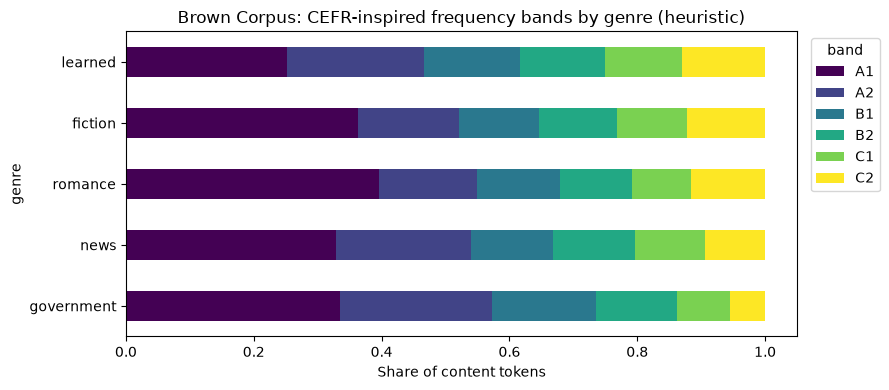

In [48]:
import matplotlib.pyplot as plt

share_cols: list[str] = [f"share_{lvl}" for lvl in CEFR_ORDER]
ax = (prof_df.groupby("genre")[share_cols].mean()
      .loc[genre_summary.index]
      .rename(columns=lambda c: c.replace("share_", ""))
      .plot(kind="barh", stacked=True, figsize=(9, 4), colormap="viridis"))
ax.set_xlabel("Share of content tokens")
ax.set_title("Brown Corpus: CEFR-inspired frequency bands by genre (heuristic)")
ax.legend(title="band", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [49]:
def suggest_level(profile: LexicalProfile, threshold: float = 0.25) -> CEFR:
    """Suggest the lowest band covering (1 - threshold) of tokens cumulatively.

    A pedagogical heuristic for selecting reading material, not an assessment.
    """
    cumulative = 0.0
    for lvl in CEFR_ORDER:
        cumulative += profile["band_share"][lvl]
        if cumulative >= 1 - threshold:
            return lvl
    return "C2"


prof_df["suggested_band"] = [suggest_level(p) for p in profiles]
pd.crosstab(prof_df["genre"], prof_df["suggested_band"]).reindex(columns=list(CEFR_ORDER), fill_value=0)

suggested_band,A1,A2,B1,B2,C1,C2
genre,,,,,,
fiction,0,0,0,10,5,0
government,0,0,7,8,0,0
learned,0,0,0,9,5,1
news,0,0,1,11,3,0
romance,0,0,0,13,2,0


## 15. Exemplo aplicado de ML: pipeline scikit-learn tipado (iris e wine)

Agora juntamos tudo: `Literal` para nomes de datasets e modelos, `dataclass` para configuração e dados, `TypedDict` para métricas, `Protocol` para estimadores e `Callable` para a fábrica de modelos.

In [50]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils import Bunch

type DatasetName = Literal["iris", "wine"]
type ModelName = Literal["logreg", "tree"]

LOADERS: Final[dict[DatasetName, Callable[[], Bunch]]] = {"iris": load_iris, "wine": load_wine}


@dataclass(frozen=True)
class DataSplit:
    """Typed container for a train/test split."""
    X_train: FloatArray
    X_test: FloatArray
    y_train: IntArray
    y_test: IntArray
    feature_names: tuple[str, ...]
    target_names: tuple[str, ...]


def load_split(name: DatasetName, cfg: ModelConfig) -> DataSplit:
    """Load a scikit-learn dataset and return a stratified split."""
    bunch = LOADERS[name]()
    X = np.asarray(bunch.data, dtype=np.float64)
    y = np.asarray(bunch.target, dtype=np.int64)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=cfg.test_size, random_state=cfg.random_state, stratify=y)
    return DataSplit(X_tr, X_te, y_tr, y_te,
                     tuple(bunch.feature_names), tuple(map(str, bunch.target_names)))


split = load_split("wine", ModelConfig())
print(split.X_train.shape, split.X_test.shape, split.target_names)

(133, 13) (45, 13) ('class_0', 'class_1', 'class_2')


In [51]:
class Classifier(Protocol):
    def fit(self, X: FloatArray, y: IntArray) -> Any: ...
    def predict(self, X: FloatArray) -> npt.NDArray[Any]: ...


MODEL_FACTORY: Final[dict[ModelName, Callable[[ModelConfig], SkPipeline]]] = {
    "logreg": lambda c: SkPipeline([("scale", StandardScaler()),
                                    ("clf", LogisticRegression(max_iter=c.max_iter, random_state=c.random_state))]),
    "tree": lambda c: SkPipeline([("clf", DecisionTreeClassifier(max_depth=4, random_state=c.random_state))]),
}


def train(cfg: ModelConfig, data: DataSplit) -> Classifier:
    """Build and fit the configured model."""
    model = MODEL_FACTORY[cfg.model](cfg)
    model.fit(data.X_train, data.y_train)
    return model


def evaluate_model(model: Classifier, data: DataSplit, name: str) -> ModelMetrics:
    """Compute typed hold-out metrics."""
    y_pred = model.predict(data.X_test)
    return ModelMetrics(
        model_name=name,
        accuracy=round(float(accuracy_score(data.y_test, y_pred)), 4),
        f1_macro=round(float(f1_score(data.y_test, y_pred, average="macro")), 4),
        n_test=int(len(data.y_test)),
    )

In [52]:
def run_experiment(dataset: DatasetName, model: ModelName, cv: int = 5) -> dict[str, Any]:
    """End-to-end typed experiment: split, train, evaluate, cross-validate."""
    cfg = ModelConfig(model=model)
    data = load_split(dataset, cfg)
    fitted = train(cfg, data)
    metrics = evaluate_model(fitted, data, f"{dataset}/{model}")
    bunch = LOADERS[dataset]()
    cv_scores = cross_val_score(MODEL_FACTORY[model](cfg), bunch.data, bunch.target, cv=cv)
    return {**metrics, "cv_mean": round(float(cv_scores.mean()), 4), "cv_std": round(float(cv_scores.std()), 4)}


results = pd.DataFrame([
    run_experiment(d, m)
    for d in get_args(DatasetName.__value__)
    for m in get_args(ModelName.__value__)
])
results

,model_name,accuracy,f1_macro,n_test,cv_mean,cv_std
0,iris/logreg,0.9211,0.9230,38,0.9600,0.0389
1,iris/tree,0.9211,0.9230,38,0.9533,0.0340
2,wine/logreg,1.0000,1.0000,45,0.9832,0.0137
3,wine/tree,0.9556,0.9565,45,0.8937,0.0472


In [53]:
# Validate every result row against the ModelMetrics TypedDict
for row in results.to_dict(orient="records"):
    core = {k: row[k] for k in ModelMetrics.__required_keys__}
    core = {k: (v.item() if hasattr(v, "item") else v) for k, v in core.items()}
    print(f"{row['model_name']:<12}", validate_typed_dict(core, ModelMetrics) or "valid ModelMetrics")

iris/logreg  valid ModelMetrics
iris/tree    valid ModelMetrics
wine/logreg  valid ModelMetrics
wine/tree    valid ModelMetrics


In [54]:
# Bonus: the same typed text pipeline on real 20 Newsgroups data
X_text: list[str] = [s.text for s in samples]
y_text: list[Label] = [s.label for s in samples]
Xtr, Xte, ytr, yte = train_test_split(X_text, y_text, test_size=0.25,
                                      random_state=RANDOM_STATE, stratify=y_text)
text_model: SkPipeline = make_text_pipeline(max_features=5000).fit(Xtr, ytr)
pred = text_model.predict(Xte)
print(f"sci.med vs sci.space — accuracy: {accuracy_score(yte, pred):.3f}, "
      f"macro-F1: {f1_score(yte, pred, average='macro'):.3f} (n_test={len(yte)})")

sci.med vs sci.space — accuracy: 0.903, macro-F1: 0.903 (n_test=289)


## 16. Resumo — o que aprendi hoje

| Recurso | Quando usar em DS/NLP | Exemplo do notebook |
|---|---|---|
| Anotações básicas | sempre, em funções públicas | `mean_tip_pct(df) -> float` |
| `list[float]`, `dict[str,int]`, `tuple[str, ...]` | vetores, vocabulários, n-gramas | `build_vocabulary`, `ngrams` |
| `X \| None` / `Optional` | dados ausentes, *lookups* que podem falhar | `parse_age` (titanic) |
| `type Alias = ...` | vocabulário de domínio reutilizável | `Corpus`, `FeatureVector`, `Label` |
| `NewType` | IDs e códigos que não devem se misturar | `UserId`, `CEFR_Level` |
| `TypeVar` / `class X[T]` | utilitários e pipelines genéricos | `batched`, `Pipeline[T]` |
| `Protocol` | interfaces estilo sklearn sem herança | `Transformer`, `Scorer` |
| `TypedDict` | registros JSON, métricas, metadados | `StudentRecord`, `ModelMetrics` |
| `Callable` | passos de pipeline, métricas, fábricas | `DataFrameStep`, `Metric` |
| `Literal` + `assert_never` | conjuntos fechados (*splits*, CEFR) | `Split`, `CEFR` |
| `@dataclass` tipada | configs imutáveis, amostras | `ModelConfig`, `TextSample` |
| Validação em *runtime* | fronteiras com dados externos | `validate_typed_dict`, `@beartype` |
| `NDArray`, `@overload`, `cast` | APIs NumPy/pandas/sklearn | `zscore`, `to_frame` |

### Lições principais

- **Type hints são documentação verificável**: o `mypy` encontrou 4 erros sem executar uma linha do módulo de demonstração.
- **Valide na fronteira, confie no interior**: dados externos passam por `isinstance`/`beartype`; o resto do código conta com a checagem estática.
- **Modele o domínio**: `Literal['A1', ..., 'C2']`, `NewType` e `TypedDict` tornam regras pedagógicas explícitas no código.
- **Seja honesto com heurísticas**: as faixas de frequência do Brown Corpus são uma *proxy* inspirada no CEFR, não níveis oficiais.

### Próximos passos

1. Adicionar `mypy --strict` (ou `pyright`) e `pandas-stubs` ao fluxo de testes (`pytest`) do repositório.
2. Explorar `pydantic` v2 para validação de dados de entrada em APIs de NLP (ex.: FastAPI do projeto Tino).
3. Estudar `pandera` para validar *schemas* de DataFrames.
4. Revisitar notebooks anteriores (OOP, decorators, itertools) adicionando anotações completas.